# EnergyMind Tunisia - Phase 1 : data checks, baseline detectors, real-fault case study

All logic lives in the tested package `src/energymind`; this notebook only drives it and plots.

**What changed versus the starter notebook**
1. Phases are pivoted first (L1/L2/L3/ALL were being mixed into one series).
2. Everything learned from data is fitted on a chronological *train* segment; thresholds are calibrated on *train / validation*, never on the test set.
3. Synthetic anomalies are *events* (spike, gain error, drift, phase loss), with ambiguous windows excluded from scoring.
4. Rules are evaluated (the starter never scored them), alongside Isolation Forest, per rule and combined.
5. The dataset's own meter-fault log is used for a real-fault case study.
6. Verdicts follow the governance policy; the invented "confidence score" is replaced by an evidence-agreement band.

> Synthetic results measure recovery of scenarios we injected. They do **not** prove real-world fault detection.

In [6]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebook lives in notebooks/

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200, "display.max_columns", 30)

from energymind.data import (load_asset_long, to_wide, load_quality_log, issue_mask, list_assets, PHASES)
from energymind.pipeline import run_synthetic_benchmark, run_real_fault_case_study
from energymind.detectors import RULE_TEXT

# Dataset folder: defaults to the filtered dataset shipped in ../dataset (override with ENERGYMIND_DATA_ROOT).
DATA_ROOT = Path(os.environ.get("ENERGYMIND_DATA_ROOT", Path.cwd().parent / "dataset"))
BENCH_ASSET = "u_e"     # regular load, no logged issues: good for the synthetic benchmark
CASE_ASSET  = "ahu_a"   # has a logged fault that starts after ~10 weeks of clean data
SEED = 42
quality_log = load_quality_log(DATA_ROOT)
print(len(list_assets(DATA_ROOT)), "assets found")

11 assets found


## 1. Load one asset and validate it

In [7]:
wide_b, rep = to_wide(load_asset_long(DATA_ROOT, BENCH_ASSET, prefer="parquet"))
for k, v in rep.items(): print(f"{k:24s} {v}")
wide_b.head()

rows_long                137708
windows_on_grid          35103
gap_windows              676
duplicate_rows_dropped   0
unparseable_timestamps   0
negative_demand_rows     0
first_window             2024-12-31 08:15:00+00:00
last_window              2025-12-31 23:45:00+00:00
phase_availability       {'L1': 0.9807423866905962, 'L2': 0.9807423866905962, 'L3': 0.9807423866905962}
unreliable_share         0.00014243796826482068


,p_L1,p_L2,p_L3,p_ALL,rel_cov,gap
window_start_utc,,,,,,
2024-12-31 08:15:00+00:00,0.061863,0.117260,0.203711,0.382834,61.666667,False
2024-12-31 08:30:00+00:00,0.301196,0.570354,0.991549,1.863100,100.000000,False
2024-12-31 08:45:00+00:00,0.300902,0.570345,0.991116,1.862362,100.000000,False
2024-12-31 09:00:00+00:00,0.300724,0.570406,0.990400,1.861530,100.000000,False
2024-12-31 09:15:00+00:00,0.261763,0.570075,0.989267,1.821105,100.000000,False


## 2. Synthetic benchmark (chronological 60 / 20 / 20 split)
Fit on train -> calibrate on validation -> inject anomalies into **test only** -> score.

In [8]:
excl = issue_mask(wide_b.index, quality_log, BENCH_ASSET)     # windows inside logged issues are blanked out
res = run_synthetic_benchmark(wide_b, BENCH_ASSET, exclude=excl if excl.any() else None, seed=SEED)
print("train/val/test windows:", len(res.train), len(res.val), len(res.test))
print("split times:", res.split_times)
print("thresholds :", {k: round(v, 3) for k, v in res.thresholds.items()})
res.events[["event_id", "anomaly_type", "phase", "start", "n_windows"]]

train/val/test windows: 21061 7021 7021
split times: (Timestamp('2025-08-07 17:30:00+0000', tz='UTC'), Timestamp('2025-10-19 20:45:00+0000', tz='UTC'))
thresholds : {'z': 14.243, 'dz': 9.233, 'share': 0.521, 'iforest': 0.604}


,event_id,anomaly_type,phase,start,n_windows
0,0,spike_drop,ALL,2025-12-06 13:45:00+00:00,2
1,1,spike_drop,ALL,2025-12-01 02:15:00+00:00,1
2,2,spike_drop,ALL,2025-12-20 05:30:00+00:00,1
3,3,spike_drop,ALL,2025-12-29 09:15:00+00:00,2
4,4,spike_drop,ALL,2025-12-13 20:15:00+00:00,2
5,5,spike_drop,ALL,2025-11-08 22:30:00+00:00,1
6,6,gain_error,L1,2025-11-21 13:30:00+00:00,43
7,7,gain_error,L2,2025-10-20 06:00:00+00:00,70
8,8,drift,L1,2025-12-02 13:00:00+00:00,82
9,9,drift,L2,2025-10-30 10:45:00+00:00,19


In [9]:
cols = ["precision", "recall", "f1", "false_alert_rate", "alerts", "pr_auc"]
print("WINDOW level (ambiguous windows excluded). Note precision is pessimistic: windows inside an event")
print("that were not labelled because the effect was negligible still count as false alerts.\n")
display(res.metrics[cols].round(3))
print("EVENT level: was each injected event noticed, and how many false incidents per day?")
display(res.event_summary[["events", "events_detected", "event_recall", "median_delay_windows",
                           "false_incidents_per_day"]].round(3))
print("Event recall by scenario type:")
display(res.event_table)

WINDOW level (ambiguous windows excluded). Note precision is pessimistic: windows inside an event
that were not labelled because the effect was negligible still count as false alerts.



,precision,recall,f1,false_alert_rate,alerts,pr_auc
detector,,,,,,
rule:PHASE_MISSING,1.000,0.551,0.711,0.000,327,NaN
rule:PHASE_SHARE_SHIFT,0.296,0.013,0.026,0.003,27,NaN
rule:SEASONAL_DEVIATION,0.000,0.000,0.000,0.001,8,NaN
rule:ABRUPT_CHANGE,0.091,0.005,0.010,0.005,33,NaN
rules (any),0.852,0.555,0.672,0.010,386,NaN
iforest,0.695,0.403,0.510,0.018,344,0.596
rules OR iforest,0.735,0.637,0.683,0.023,514,NaN
rules AND iforest,0.880,0.320,0.470,0.004,216,NaN


EVENT level: was each injected event noticed, and how many false incidents per day?


,events,events_detected,event_recall,median_delay_windows,false_incidents_per_day
detector,,,,,
rule:PHASE_MISSING,15,4,0.267,1.0,0.000
rule:PHASE_SHARE_SHIFT,15,1,0.067,63.0,0.055
rule:SEASONAL_DEVIATION,15,0,0.000,NaN,0.027
rule:ABRUPT_CHANGE,15,3,0.200,12.0,0.356
rules (any),15,6,0.400,1.0,0.438
iforest,15,9,0.600,3.0,0.697
rules OR iforest,15,9,0.600,1.0,0.902
rules AND iforest,15,5,0.333,2.0,0.205


Event recall by scenario type:


anomaly_type,drift,gain_error,phase_loss,spike_drop
detector,,,,
iforest,0.67,1.0,1.00,0.17
rule:ABRUPT_CHANGE,0.33,0.5,0.25,0.00
rule:PHASE_MISSING,0.00,0.0,1.00,0.00
rule:PHASE_SHARE_SHIFT,0.00,0.0,0.25,0.00
rule:SEASONAL_DEVIATION,0.00,0.0,0.00,0.00
rules (any),0.33,0.5,1.00,0.00
rules AND iforest,0.00,0.5,1.00,0.00
rules OR iforest,0.67,1.0,1.00,0.17


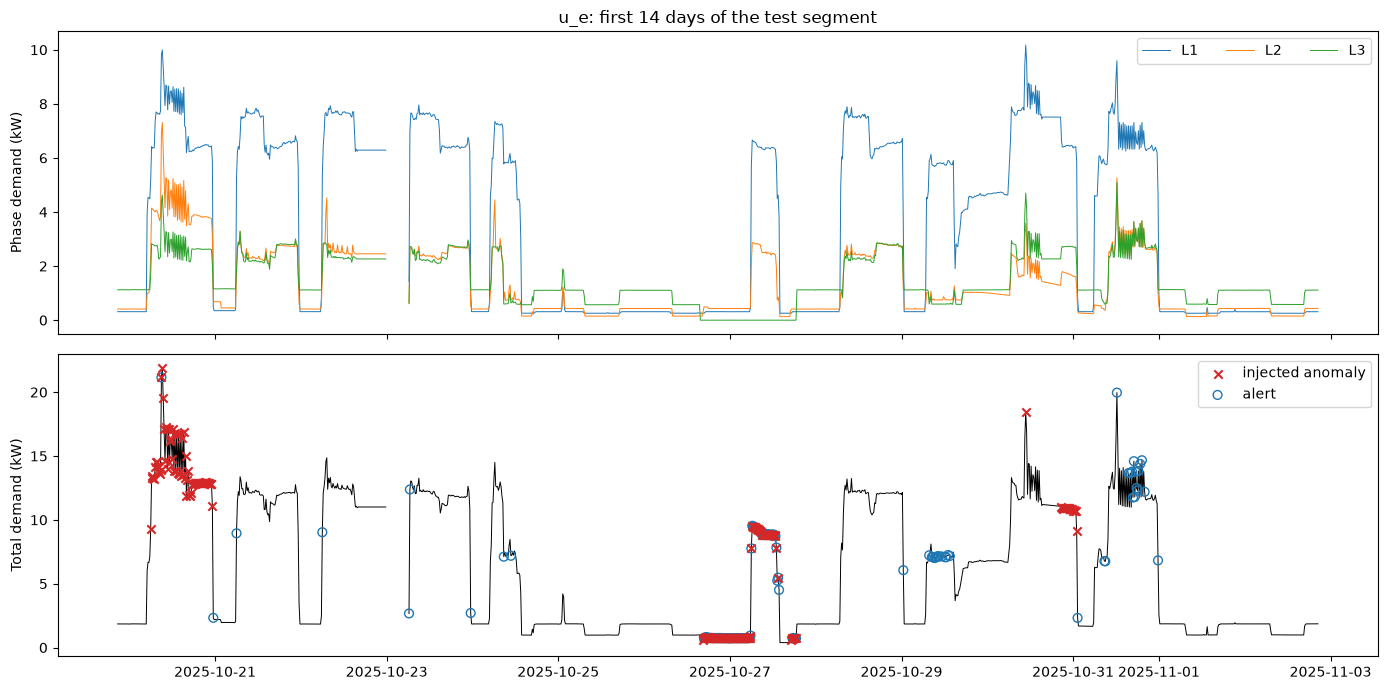

In [10]:
f = res.test.join(res.labels)
seg = f.iloc[: 96 * 14]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ph in PHASES: axes[0].plot(seg.index, seg[f"p_{ph}"], lw=0.7, label=ph)
axes[0].set_ylabel("Phase demand (kW)"); axes[0].legend(ncol=3); axes[0].set_title(f"{BENCH_ASSET}: first 14 days of the test segment")
axes[1].plot(seg.index, seg["p_ALL"], lw=0.7, color="k")
inj = seg["is_injected"] == 1
axes[1].scatter(seg.index[inj], seg.loc[inj, "p_ALL"], marker="x", c="tab:red", label="injected anomaly", zorder=3)
al = res.decisions.loc[seg.index, "verdict"] != "ROUTINE"
axes[1].scatter(seg.index[al], seg.loc[al, "p_ALL"], facecolors="none", edgecolors="tab:blue", s=40, label="alert", zorder=2)
axes[1].set_ylabel("Total demand (kW)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. Real-fault case study from the dataset's own quality log
For `ahu_a` the log records an L3 power-tag misconfiguration starting 2025-03-10. We fit on the **clean period before it**, then score everything after.

Caveats: the log has asset-level intervals and no timezone (assumed UTC); there is no clean data *after* the issue, so false alerts cannot be measured out-of-sample (alert rate on the clean validation slice is shown instead); and using the pre-issue period as baseline stands in for a known-good commissioning period.

In [11]:
wide_a, _ = to_wide(load_asset_long(DATA_ROOT, CASE_ASSET, prefer="parquet"))
cs = run_real_fault_case_study(wide_a, quality_log, CASE_ASSET, seed=SEED)
print("First logged issue start:", cs.issue_start)
print(quality_log.loc[quality_log.asset_id == CASE_ASSET, ["issue_type", "issue_detail"]].to_string(index=False))
display(cs.summary.round(3))

First logged issue start: 2025-03-10 09:22:00+00:00
          issue_type                                                                                                                         issue_detail
tag_misconfiguration L3 power tag misconfiguration; had been correctly set originally but may have been overwritten during dashboard development updates.


,alert_rate_clean_validation,share_of_issue_windows_flagged,first_alert_after_issue_start
detector,,,
PHASE_MISSING,0.000,1.000,2025-03-10 09:45:00+00:00
PHASE_SHARE_SHIFT,0.094,0.865,2025-03-10 10:00:00+00:00
SEASONAL_DEVIATION,0.000,0.000,NaT
ABRUPT_CHANGE,0.000,0.000,NaT
rules (any),0.094,1.000,2025-03-10 09:45:00+00:00
iforest,0.010,0.002,2025-03-10 09:30:00+00:00


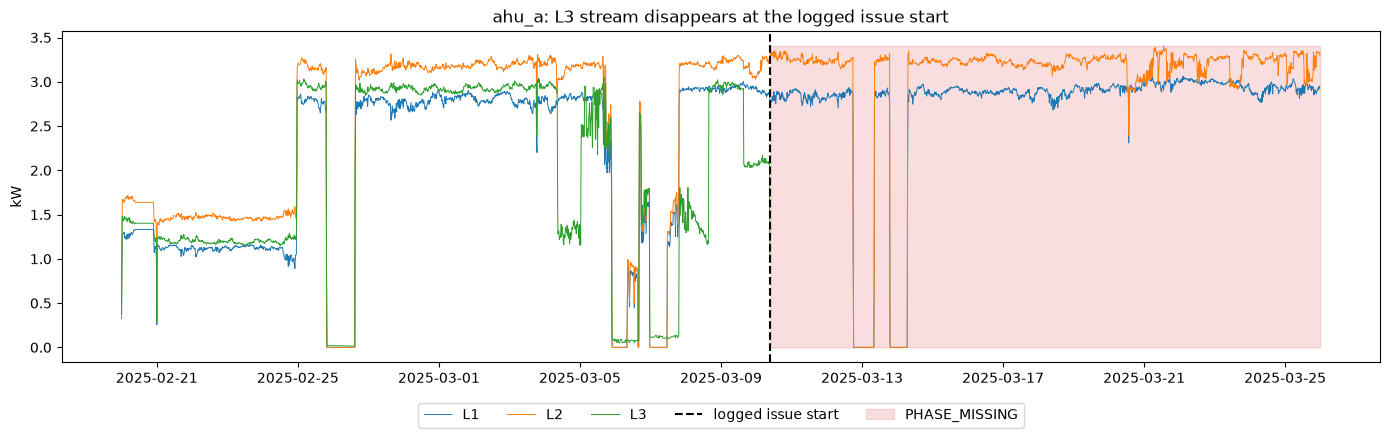

In [12]:
w = wide_a.loc["2025-02-20":"2025-03-25"]
fig, ax = plt.subplots(figsize=(14, 4.5))
for ph in PHASES: ax.plot(w.index, w[f"p_{ph}"], lw=0.7, label=ph)
ax.axvline(cs.issue_start, color="k", ls="--", label="logged issue start")
flag = cs.rules["PHASE_MISSING"].loc[w.index]
ax.fill_between(w.index, 0, w[[f"p_{p}" for p in PHASES]].max().max(), where=flag, alpha=0.15, color="tab:red", label="PHASE_MISSING")
ax.set_title(f"{CASE_ASSET}: L3 stream disappears at the logged issue start"); ax.set_ylabel("kW"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

## 4. Audit log (one row per incident)
Reviewer fields are blank on purpose: they are filled by the human reviewer. `URGENT_ASSESSMENT` is never assigned automatically; that threshold must be agreed with a qualified facility operator.

In [13]:
audit = res.audit_log
audit.to_csv("energymind_phase1_audit_log.csv", index=False)
print(len(audit), "incidents ->", "energymind_phase1_audit_log.csv")
print("(the audit log contains no synthetic labels; those stay in the evaluation tables)")
audit.drop(columns=["rule_evidence"]).head(8)

83 incidents -> energymind_phase1_audit_log.csv
(the audit log contains no synthetic labels; those stay in the evaluation tables)


,event_id,asset_id,start_utc,end_utc,n_alert_windows,model_flagged,peak_model_score,evidence_agreement,verdict,recommended_action,human_review_required,model_version,reviewer_outcome,reviewed_at_utc
0,EM-u_e-00001,u_e,2025-10-20 09:00:00+00:00,2025-10-20 09:00:00+00:00,1,True,0.644113,HIGH,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,
1,EM-u_e-00002,u_e,2025-10-20 23:30:00+00:00,2025-10-20 23:30:00+00:00,1,False,0.592464,LOW,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,
2,EM-u_e-00003,u_e,2025-10-21 06:00:00+00:00,2025-10-21 06:00:00+00:00,1,False,0.523087,LOW,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,
3,EM-u_e-00004,u_e,2025-10-22 06:00:00+00:00,2025-10-22 06:00:00+00:00,1,False,0.521041,LOW,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,
4,EM-u_e-00005,u_e,2025-10-23 00:00:00+00:00,2025-10-23 06:30:00+00:00,27,False,0.526616,LOW,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,
5,EM-u_e-00006,u_e,2025-10-23 23:30:00+00:00,2025-10-23 23:30:00+00:00,1,True,0.616287,HIGH,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,
6,EM-u_e-00007,u_e,2025-10-24 08:45:00+00:00,2025-10-24 08:45:00+00:00,1,True,0.643955,LOW,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,
7,EM-u_e-00008,u_e,2025-10-24 10:45:00+00:00,2025-10-24 10:45:00+00:00,1,True,0.608630,LOW,OPERATOR_REVIEW,Operator should review the evidence before any...,True,phase1-rules+iforest-v0.2.0,,


## 5. Reading the results honestly
- **Isolation Forest vs rules are complementary.** Across the assets of the benchmark (run `scripts/run_benchmark.py`), the forest finds more injected events, while `PHASE_MISSING` is near-silent on clean data and was the only detector that reliably caught the *real* logged faults.
- **Rules are not magic.** `SEASONAL_DEVIATION` and `ABRUPT_CHANGE` are weak on loads with large normal variability; thresholds come from the data, so they loosen exactly where normal behaviour is noisy.
- **Idle/burst assets** (e.g. `mix_a`, `mix_d`) are skipped or unreliable for this baseline.
- **15-minute aggregates** cannot reveal short electrical transients.
- Evidence-agreement bands are **not probabilities**; calibration needs labelled validation data.